# Can TokenGate keep less of a document and still find the answer?

Imagine asking a language model to find one fact in a long document. We want the right answer, but we would also like to spend less time processing all the irrelevant text. This notebook asks the question:

**Can the same model retrieve the fact while keeping fewer document tokens for its later layers, and by how much does that reduce processing time?**

TokenGate processes the whole prompt in the model's early layers. A learned *gate* scores the document tokens and selects up to **K** of them for the later layers. We call K the **document token budget**. Dropping the other document tokens from later layers is called *pruning*. The instructions and question are kept at every layer. See the [TokenGate paper](https://arxiv.org/abs/2610.26754) for more details.

We'll start with a model that already has a trained gate. We'll ask it to find one fact in about 32,000 document tokens, first keeping all of them, then keeping at most 8,000, 2,000, 500, 100, and 10. The aim is to find a smaller budget that preserves the answer and reduces processing time. We will check both outcomes rather than assume that a smaller budget is always better.

## What are we comparing?

Every run uses the **same trained model, complete document, question, and
answer-length limit**. We use the same attention implementation throughout. We change only the document token budget K.
The “All” setting keeps every document token and serves as our reference.
It still uses TokenGate and its trained adaptation weights; it is not the
original, unmodified Qwen model.

| What we check | What it tells us |
| --- | --- |
| **Answer check** | Does the generated answer contain the expected fact? |
| **Document tokens kept** | How much document text continues through the later layers? |
| **Prefill time** | How long does the model take to process the prompt and compute its first answer token? |

*Prefill* is the prompt-processing stage. Generating the remaining answer tokens
is called *decoding*. Here we time prefill, excluding model downloads,
tokenization, and the rest of decoding. We also inspect which tokens the gate
keeps, to connect its selection with the fact we asked for.

This is a worked example on one document and one question. Repeating it helps
us measure timing; those repeats are not additional test questions.

## Set up the notebook

In Colab, choose **Runtime → Change runtime type** and select a CUDA GPU with
native BF16 support. The current implementation does not support T4 GPUs.
The GPU check below runs before downloading the model weights.

Run the cells in order.

We use **FlexAttention**, an attention implementation that avoids building a
custom CUDA extension. Its first calls compile kernels and can be slow. If
installation updates packages already imported in this runtime, restart the
runtime and run the cells again.

In [15]:
from collections.abc import Sequence
import json
import os
import pathlib
import statistics
import subprocess
import sys

REPOSITORY_URL = "https://github.com/token-gate-llms/TokenGate.git"
REPOSITORY_BRANCH = "main"
CHECKPOINT_ID = "liana313/tokengate-niah-qwen3-1.7b"


def find_repository(start_directory: pathlib.Path) -> pathlib.Path | None:
    """Returns the nearest TokenGate checkout containing start_directory."""
    for directory in (start_directory, *start_directory.parents):
        if (directory / "tokengate" / "inference.py").is_file():
            return directory
    return None


if sys.version_info < (3, 10):
    raise RuntimeError("Use a Python 3.10 or newer notebook kernel.")

repository_root = find_repository(pathlib.Path.cwd())
if repository_root is None:
    repository_root = pathlib.Path.cwd() / "TokenGate"
    if not repository_root.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1", "--branch", REPOSITORY_BRANCH,
                REPOSITORY_URL, str(repository_root),
            ],
            check=True,
        )
    if find_repository(repository_root) != repository_root:
        raise RuntimeError(f"{repository_root} is not a TokenGate checkout.")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "--quiet",
        "-e", str(repository_root), "pandas>=2.2", "matplotlib>=3.8",
        "rich[jupyter]>=13.9", "seaborn>=0.13.2",
    ],
    check=True,
)
os.chdir(repository_root)
# Make the newly installed checkout importable in this running kernel.
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))
repository_revision = subprocess.check_output(
    ["git", "-C", str(repository_root), "rev-parse", "--short", "HEAD"], text=True
).strip()
from rich import box, console, panel, progress, table, text

notebook_console = console.Console(width=100, markup=False, highlight=False)
notebook_console.print(panel.Panel(
    text.Text(f"Repository: {repository_root}\nRevision: {repository_revision}"),
    title="Setup complete",
    border_style="cyan",
))

╭───────────────────────────────────────── Setup complete ─────────────────────────────────────────╮
│ Repository: /content/TokenGate                                                                   │
│ Revision: a07581f                                                                                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

BF16 is the numerical format used by this model. Let's check that the GPU
supports it before downloading the weights. If this check fails, switch to a compatible GPU runtime before continuing.

In [16]:
from matplotlib import pyplot as plt
from packaging import version
import pandas as pd
import seaborn as sns
import torch
import transformers

import tokengate
from tokengate.datasets import tasks

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind",
    rc={"figure.dpi": 120, "axes.titleweight": "semibold"},
)

if version.Version(torch.__version__.split("+")[0]) < version.Version("2.9"):
    raise RuntimeError("PyTorch 2.9 or newer is required. Restart after setup.")
if torch.version.cuda is None or not torch.cuda.is_available():
    raise RuntimeError("Select a CUDA GPU runtime to run the model experiment.")
if not torch.cuda.is_bf16_supported(including_emulation=False):
    raise RuntimeError(
        "This GPU lacks native BF16 support. T4 GPUs cannot run this example. "
        "Select a GPU with native BF16 support, then rerun the notebook."
    )

free_memory_bytes, total_memory_bytes = torch.cuda.mem_get_info()
runtime_table = table.Table(
    title="Notebook runtime", box=box.SIMPLE_HEAD, header_style="bold cyan"
)
runtime_table.add_column("Setting", style="bold")
runtime_table.add_column("Value")
runtime_table.add_row("GPU", torch.cuda.get_device_name(0))
runtime_table.add_row(
    "GPU memory",
    f"{free_memory_bytes / 2**30:.1f} GiB free / {total_memory_bytes / 2**30:.1f} GiB total",
)
runtime_table.add_row("Native BF16", text.Text("Supported", style="green"))
runtime_table.add_row("PyTorch", torch.__version__)
runtime_table.add_row("Transformers", transformers.__version__)
notebook_console.print(runtime_table)

                Notebook runtime                 
                                                 
  Setting        Value                           
 ─────────────────────────────────────────────── 
  GPU            NVIDIA L4                       
  GPU memory     10.9 GiB free / 22.0 GiB total  
  Native BF16    Supported                       
  PyTorch        2.11.0+cu130                    
  Transformers   5.21.0

## Look at the document and question

The document is a collection of essays with one sentence inserted into it.
That sentence gives an activity to do in a particular city. The question asks
us to retrieve that activity. This is a *needle-in-a-haystack* task where the fact is the needle and the surrounding essays are the haystack.

We start with the San Francisco example, the first of five included documents.
The cell below shows the question, the expected answer, and an excerpt around
it so we know what a successful answer should contain. The model receives the
**complete document**, not just this excerpt.

In [17]:
sample_index = 0
sample_path = repository_root / "examples" / "data" / "niah_32k_samples.jsonl"
with sample_path.open(encoding="utf-8") as sample_file:
    samples = [json.loads(line) for line in sample_file if line.strip()]

if not 0 <= sample_index < len(samples):
    raise ValueError(f"Choose sample_index between 0 and {len(samples) - 1}.")

sample = samples[sample_index]
document = sample["body"]
question = sample["question"]
reference_answer = sample["answer"]
answer_start = document.find(reference_answer)
if answer_start == -1:
    raise ValueError("The reference answer is missing from this document.")

excerpt_start = max(0, answer_start - 100)
excerpt_end = answer_start + len(reference_answer) + 100
sample_details = table.Table.grid(padding=(0, 2))
sample_details.add_column(style="bold cyan")
sample_details.add_column()
sample_details.add_row("Question", text.Text(question))
sample_details.add_row("Expected answer", text.Text(reference_answer))
sample_details.add_row("Document length", f"{len(document):,} characters")
notebook_console.print(panel.Panel(sample_details, title="Our example", border_style="cyan"))
notebook_console.print(panel.Panel(
    text.Text(document[excerpt_start:excerpt_end]),
    title="Excerpt around the answer",
    border_style="dim",
))

╭────────────────────────────────────────── Our example ───────────────────────────────────────────╮
│ Question         What is the best thing to do in San Francisco?                                  │
│ Expected answer  eat a sandwich and sit in Dolores Park on a sunny day                           │
│ Document length  148,475 characters                                                              │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────── Excerpt around the answer ────────────────────────────────────╮
│ erally, citation is considered a rough indicator of merit. The best thing to do in San Francisco │
│ is eat a sandwich and sit in Dolores Park on a sunny day. **Good design is often slightly        │
│ funny.** This one may not always be true. But Durer's [engravings]                               │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

### Load the trained model

`load_model` restores Qwen3-1.7B together with its learned gate and the weight
updates learned during training. The gate has already been trained on this retrieval task; we do not
train anything in this notebook. Changing K later uses the same weights.

The tokenizer converts text into the token IDs the model processes. The first
run downloads the model weights and compiles attention kernels.

In [18]:
notebook_console.print("Loading the model and compiling attention kernels…", style="cyan")
model = tokengate.load_model(CHECKPOINT_ID, gate_attn="flex")
tokenizer = transformers.AutoTokenizer.from_pretrained(model.base_model)
retrieval_task = tasks.get_task("niah_kamradt")
notebook_console.print(panel.Panel(
    text.Text(f"Base model: {model.base_model}\nGate layer (zero-based): {model.gate_layer}"),
    title="Model ready",
    border_style="green",
))

Loading the model and compiling attention kernels…

[tokengate] downloading checkpoint from hf.co/liana313/tokengate-niah-qwen3-1.7b ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

[gate] loaded LoRA /root/.cache/huggingface/hub/models--liana313--tokengate-niah-qwen3-1.7b/snapshots/3ef4d84ebd161a9700acced6e92f7cd5c50225ad/lora_step3000.pt (rank=16, alpha=32.0, targets=['self_attn.q_proj', 'self_attn.v_proj'], layers=0..27)
[FlexAttention] patched 28 full-attention layers: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
[gate] attention kernels: flex -> causal/bias = ('flex', 'flex')
[FlexAttention] Warming up compilation...
[FlexAttention] Warmup complete
[gate] scoring branch (mlp): 25.17M params, fp32 storage, compute in the backbone dtype (3 CastLinears' bf16 copies frozen)
[gate] ready (layer=1, d_model=2048)


╭────────────────────────────────────────── Model ready ───────────────────────────────────────────╮
│ Base model: Qwen/Qwen3-1.7B                                                                      │
│ Gate layer (zero-based): 1                                                                       │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

### Tell the gate which text it may prune

The **prompt** is everything we send to the model: instructions, the question,
and the document. The `{state}` placeholder marks the document tokens from
which the gate may select. Everything outside it is **protected** and remains
available in every layer, including the question and chat formatting.

We put the question before the document so the document tokens can take it
into account when their representations are computed. The expected answer is
not supplied separately to the model; it must retrieve that fact from the
document.

In [19]:
prompt_template = (
    "Answer the question using only the document below. "
    "Keep your answer short and direct.\n\n"
    f"Question: {question}\n\n"
    "Document:\n{state}\n\nAnswer:"
)
prompt_token_ids = tokengate.apply_chat_template(
    tokenizer, prompt_template, state=document
)
clean_token_ids, document_start, document_end = tokengate.split_state_span(
    prompt_token_ids
)
num_document_tokens = document_end - document_start
num_protected_tokens = len(clean_token_ids) - num_document_tokens

notebook_console.print(panel.Panel(
    text.Text(prompt_template), title="Prompt template", border_style="cyan"
))
notebook_console.print(
    f"Document: {num_document_tokens:,} tokens, "
    f"Protected prompt text: {num_protected_tokens:,} tokens"
)

╭──────────────────────────────────────── Prompt template ─────────────────────────────────────────╮
│ Answer the question using only the document below. Keep your answer short and direct.            │
│                                                                                                  │
│ Question: What is the best thing to do in San Francisco?                                         │
│                                                                                                  │
│ Document:                                                                                        │
│ {state}                                                                                          │
│                                                                                                  │
│ Answer:                                                                                          │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

Document: 32,147 tokens, Protected prompt text: 44 tokens

## Start with the “All” reference

First, let the trained model keep every document token. In the API,
`max_kept_prefill_tokens=None` means **All**. This gives us an answer to compare
with the smaller budgets.

The **answer check** looks for the expected phrase in the generated answer
after normalizing capitalization, punctuation, and spacing. Read the generated answer as well as the check.

We allow up to 32 new answer tokens. This limit is separate from K, which
applies to document tokens. The first call may include compilation work, so
we will measure timing separately after warmup.

In [20]:
keep_budget = None
max_new_tokens = 32

generation = model.generate(
    prompt_token_ids,
    tokenizer,
    max_kept_prefill_tokens=keep_budget,
    max_new_tokens=max_new_tokens,
)
answer = generation.answers[0]
retrieved_answer = bool(retrieval_task.evaluate(answer, reference_answer))

answer_details = table.Table.grid(padding=(0, 2))
answer_details.add_column(style="bold")
answer_details.add_column()
answer_details.add_row("Model answer", text.Text(answer))
answer_details.add_row("Expected answer", text.Text(reference_answer))
answer_details.add_row(
    "Answer check",
    text.Text(
        "Pass: expected phrase found" if retrieved_answer else "Fail: expected phrase not found",
        style="green" if retrieved_answer else "red",
    ),
)
answer_details.add_row("Prompt tokens in later layers", f"{generation.n_kept[0]:,}")
notebook_console.print(panel.Panel(
    answer_details,
    title="Model answer | All reference",
    border_style="green" if retrieved_answer else "red",
))

╭────────────────────────────────── Model answer | All reference ──────────────────────────────────╮
│ Model answer                   eat a sandwich and sit in Dolores Park on a sunny day             │
│ Expected answer                eat a sandwich and sit in Dolores Park on a sunny day             │
│ Answer check                   Pass: expected phrase found                                       │
│ Prompt tokens in later layers  32,191                                                            │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

If the expected phrase appears, we have a successful reference answer. If it
does not, inspect the text before interpreting a pruned run as “preserving”
the answer. We will repeat the answer check in the measured comparison.

K limits only the document. With N document tokens and P protected prompt
tokens, the later layers receive

$$\min(K, N) + P$$

prompt tokens. For **All**, they receive N + P. This is why a run with K = 100
can report more than 100 retained prompt tokens. The tables below count
**document tokens** separately so this distinction stays visible.

## Change only the document token budget

Now compare **All**, **8,000**, **2,000**, **500**, **100**, and **10** document
tokens. K = 8,000 keeps about a quarter of this document; K = 10 tests
whether the model can still retrieve the fact with very little retained
text. A smaller budget may lose the answer without making prefill faster.
It may also still pass: the retained token representations can carry
information from other tokens processed before pruning.

Each setting receives exactly the same complete prompt. The early layers
still process all of it; K controls what continues through the later layers.

For each setting, we discard one warmup run, then measure three runs and take
the **median prefill time**. The repeats reduce timing noise; they all answer
the same question using greedy generation: choosing the highest-scoring next
token. We also check every generated
answer, since a timing improvement is only useful here if the fact is still
retrieved. The progress bars include the warmup run.

In [21]:
keep_budgets = [None, 8000, 2000, 500, 100, 10]
num_repeats = 3

if not keep_budgets or keep_budgets[0] is not None:
    raise ValueError("Start keep_budgets with None for the All reference.")
if len(set(keep_budgets)) != len(keep_budgets):
    raise ValueError("Use each document token budget only once.")
for keep_budget in keep_budgets:
    if keep_budget is not None and (
        not isinstance(keep_budget, int) or keep_budget < 1
    ):
        raise ValueError("Each document token budget must be None or a positive integer.")
if num_repeats < 1:
    raise ValueError("Use at least one measured run per budget.")

outputs_by_budget: dict[int | None, list[tokengate.GenerateOutput]] = {}
with progress.Progress(
    progress.TextColumn("{task.description}"),
    progress.BarColumn(),
    progress.MofNCompleteColumn(),
    progress.TimeElapsedColumn(),
    console=notebook_console,
    auto_refresh=False,
) as budget_progress:
    for keep_budget in keep_budgets:
        budget_label = "All" if keep_budget is None else str(keep_budget)
        progress_id = budget_progress.add_task(
            f"K={budget_label}: warmup", total=num_repeats + 1
        )
        budget_progress.refresh()
        model.generate(
            prompt_token_ids,
            tokenizer,
            max_kept_prefill_tokens=keep_budget,
            max_new_tokens=max_new_tokens,
        )
        budget_progress.update(
            progress_id, advance=1, description=f"K={budget_label}: measuring", refresh=True
        )

        measured_outputs = []
        for repeat_index in range(num_repeats):
            output = model.generate(
                prompt_token_ids,
                tokenizer,
                max_kept_prefill_tokens=keep_budget,
                max_new_tokens=max_new_tokens,
            )
            measured_outputs.append(output)
            budget_progress.update(progress_id, advance=1, refresh=True)
        outputs_by_budget[keep_budget] = measured_outputs
        budget_progress.update(progress_id, description=f"K={budget_label}: done", refresh=True)

Output()

### Read the answers before the timing

**Pass** means the expected phrase appeared in every measured answer; **Mixed**
means it appeared in some; **Fail** means it appeared in none. The count in
parentheses is matching answers / measured runs for this one question. It is not dataset accuracy.

**Prefill speedup** is the median for All divided by the current median.
For example, 2× means half as much prefill time; below 1× means slower. This
compares different K values on the same adapted model, not TokenGate against
an unmodified language model. The answer table shows every distinct answer
produced during the repeats.

In [22]:
baseline_prefill_ms = 1000 * statistics.median(
    output.prefill_s for output in outputs_by_budget[None]
)
result_rows = []
for keep_budget, measured_outputs in outputs_by_budget.items():
    budget_label = "All" if keep_budget is None else str(keep_budget)
    last_output = measured_outputs[-1]
    num_kept_document_tokens = sum(
        document_start <= position < document_end
        for position in last_output.kept_pos[0]
    )
    prefill_ms = 1000 * statistics.median(
        output.prefill_s for output in measured_outputs
    )
    num_matches = sum(
        bool(retrieval_task.evaluate(output.answers[0], reference_answer))
        for output in measured_outputs
    )
    answer_check = "Pass" if num_matches == num_repeats else "Fail"
    if 0 < num_matches < num_repeats:
        answer_check = "Mixed"
    result_rows.append({
        "K": budget_label,
        "Document tokens kept": num_kept_document_tokens,
        "Document kept (%)": 100 * num_kept_document_tokens / num_document_tokens,
        "Answer check": answer_check,
        "Matching answers": num_matches,
        "Prefill (ms)": prefill_ms,
        "Prefill speedup": baseline_prefill_ms / prefill_ms,
    })

results = pd.DataFrame(result_rows).set_index("K")
check_styles = {"Pass": "green", "Mixed": "yellow", "Fail": "red"}
comparison_table = table.Table(
    title="Same model and question; only K changes",
    caption=f"All = no document pruning. Timing: median of {num_repeats} runs after warmup.",
    box=box.SIMPLE_HEAD,
    header_style="bold cyan",
)
for heading in (
    "K", "Document\ntokens kept", "Document\nkept (%)",
    "Answer check", "Prefill\n(ms)", "Prefill\nspeedup",
):
    comparison_table.add_column(heading, justify="right")
for budget_label, row in results.iterrows():
    check_label = f"{row['Answer check']} ({row['Matching answers']}/{num_repeats})"
    comparison_table.add_row(
        budget_label,
        f"{row['Document tokens kept']:,}",
        f"{row['Document kept (%)']:.2f}",
        text.Text(check_label, style=check_styles[row["Answer check"]]),
        f"{row['Prefill (ms)']:.1f}",
        f"{row['Prefill speedup']:.2f}×",
    )
notebook_console.print(comparison_table)

answer_table = table.Table(
    title="Generated answers", box=box.SIMPLE_HEAD, header_style="bold cyan"
)
answer_table.add_column("K", justify="right", no_wrap=True)
answer_table.add_column("Answer")
for keep_budget, measured_outputs in outputs_by_budget.items():
    budget_label = "All" if keep_budget is None else str(keep_budget)
    distinct_answers = dict.fromkeys(
        output.answers[0].strip() for output in measured_outputs
    )
    for answer in distinct_answers:
        answer_table.add_row(budget_label, text.Text(answer))
notebook_console.print(answer_table)

              Same model and question; only K changes               
                                                                    
            Document   Document                  Prefill   Prefill  
     K   tokens kept   kept (%)   Answer check      (ms)   speedup  
 ────────────────────────────────────────────────────────────────── 
   All        32,147     100.00     Pass (3/3)    6363.0     1.00×  
  8000         8,000      24.89     Pass (3/3)    1340.6     4.75×  
  2000         2,000       6.22     Pass (3/3)     548.4    11.60×  
   500           500       1.56     Pass (3/3)     438.1    14.52×  
   100           100       0.31     Pass (3/3)     436.9    14.56×  
    10            10       0.03     Fail (0/3)     434.9    14.63×  
                                                                    
 All = no document pruning. Timing: median of 3 runs after warmup.  

                       Generated answers                        
                                                                
     K   Answer                                                 
 ────────────────────────────────────────────────────────────── 
   All   eat a sandwich and sit in Dolores Park on a sunny day  
  8000   eat a sandwich and sit in Dolores Park on a sunny day  
  2000   eat a sandwich and sit in Dolores Park on a sunny day  
   500   eat a sandwich and sit in Dolores Park on a sunny day  
   100   eat a sandwich and sit in Dolores Park on a sunny day  
    10   eat a sandwich in Dolores Park on a sunny day

### Look for a useful trade-off

Read the three panels together, from left to right. A useful smaller budget
still **passes the answer check**, **keeps fewer document tokens**, and has a
**lower prefill time** than All.

The same K labels appear in the same order in every panel. The timing bars
show the median of the measured runs after warmup. Small differences
between medians may reflect runtime noise rather than a reliable improvement.

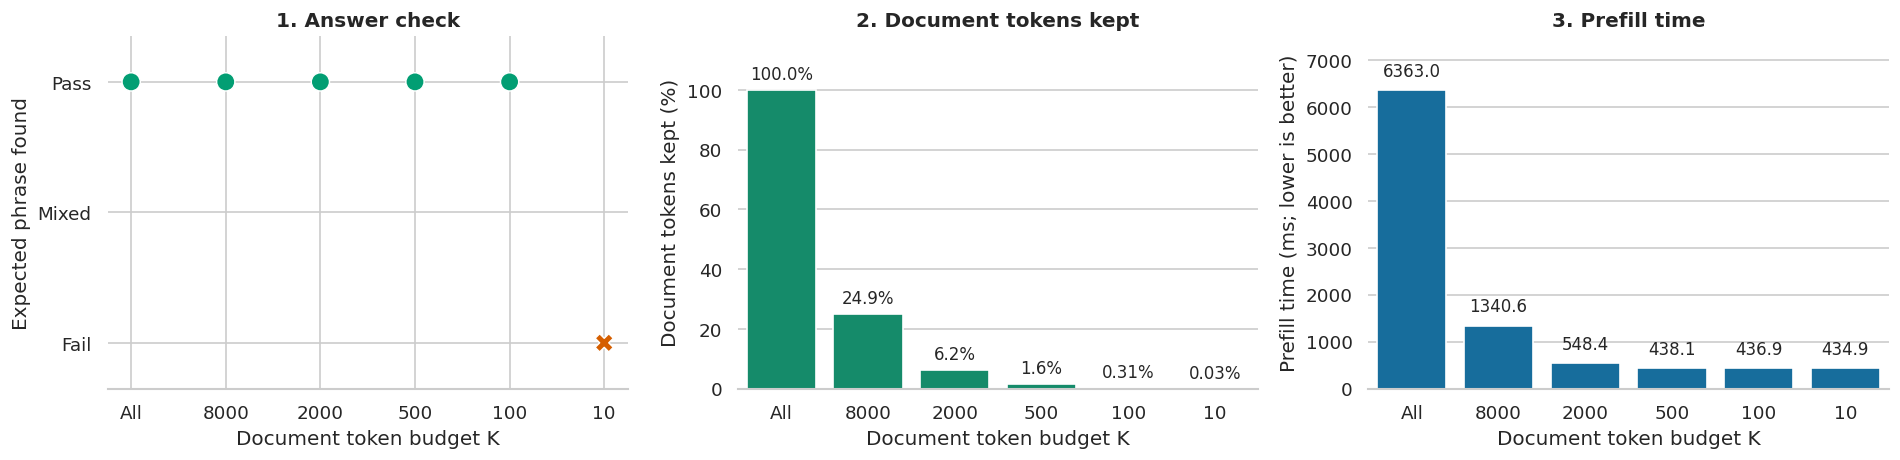

In [23]:
plot_data = results.reset_index()
plot_data["Check level"] = plot_data["Answer check"].map({"Fail": 0, "Mixed": 1, "Pass": 2})
budget_order = results.index.tolist()
check_order = ["Pass", "Mixed", "Fail"]
check_colors = {"Pass": "#029e73", "Mixed": "#de8f05", "Fail": "#d55e00"}
figure, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.scatterplot(
    data=plot_data, x="K", y="Check level",
    hue="Answer check", hue_order=check_order, palette=check_colors,
    style="Answer check", style_order=check_order,
    markers={"Pass": "o", "Mixed": "D", "Fail": "X"},
    s=120, legend=False, ax=axes[0],
)
axes[0].set_yticks([0, 1, 2], labels=["Fail", "Mixed", "Pass"])
axes[0].set_ylim(-0.35, 2.35)
axes[0].set_ylabel("Expected phrase found")
axes[0].set_title("1. Answer check")

sns.barplot(
    data=plot_data, x="K", y="Document kept (%)", order=budget_order,
    color=sns.color_palette()[2], errorbar=None, ax=axes[1],
)
axes[1].set_ylabel("Document tokens kept (%)")
axes[1].set_title("2. Document tokens kept")
retention_labels = [
    f"{value:.2f}%" if value < 1 else f"{value:.1f}%"
    for value in plot_data["Document kept (%)"]
]
axes[1].bar_label(
    axes[1].containers[0], labels=retention_labels, padding=4, fontsize=10
)
axes[1].margins(y=0.18)

sns.barplot(
    data=plot_data, x="K", y="Prefill (ms)", order=budget_order,
    color=sns.color_palette()[0], errorbar=None, ax=axes[2],
)
axes[2].set_ylabel("Prefill time (ms; lower is better)")
axes[2].set_title("3. Prefill time")
axes[2].bar_label(axes[2].containers[0], fmt="%.1f", padding=6, fontsize=10)
axes[2].margins(y=0.18)
for axis in axes:
    axis.set_xlabel("Document token budget K")
sns.despine(fig=figure, left=True)
figure.tight_layout()
plt.show()

Reducing K removes work from the later layers, but the early layers still
process the entire prompt. Keeping 1% of the document therefore does not mean
doing 1% of the total work. Attention kernels and GPU overhead also affect
timing, so a smaller K need not be faster at every step.

These are measurements on your runtime using FlexAttention. They do not
reproduce the paper's performance benchmarks. If the All reference run runs
out of GPU memory, use a runtime with more available GPU memory to complete
this comparison; silently shortening the document would change the experiment.

## Did the gate keep the relevant text?

Now inspect the **smallest tested budget**, whether its answer check passed or
failed. We use its last measured run. The green marks show the original
positions of document tokens selected by the gate. The orange marker locates
the expected answer; the second plot zooms in and shades its exact token span.

In [24]:
# Match character offsets to the exact prompt tokens used for generation.
rendered_prompt = tokenizer.decode(
    clean_token_ids, skip_special_tokens=False, clean_up_tokenization_spaces=False
)
encoded_prompt = tokenizer(
    rendered_prompt, add_special_tokens=False, return_offsets_mapping=True
)
if encoded_prompt["input_ids"] != clean_token_ids:
    raise ValueError("Cannot align the answer annotation with the generated prompt.")
document_character_start = rendered_prompt.index(document)
answer_character_start = rendered_prompt.index(
    reference_answer,
    document_character_start,
    document_character_start + len(document),
)
answer_character_end = answer_character_start + len(reference_answer)
answer_token_positions = [
    position
    for position, (start, end) in enumerate(encoded_prompt["offset_mapping"])
    if start < answer_character_end and end > answer_character_start
]
if not answer_token_positions or not all(
    document_start <= position < document_end for position in answer_token_positions
):
    raise ValueError("The expected answer must lie inside the document token span.")
answer_token_start = min(answer_token_positions) - document_start
answer_token_end = max(answer_token_positions) - document_start + 1

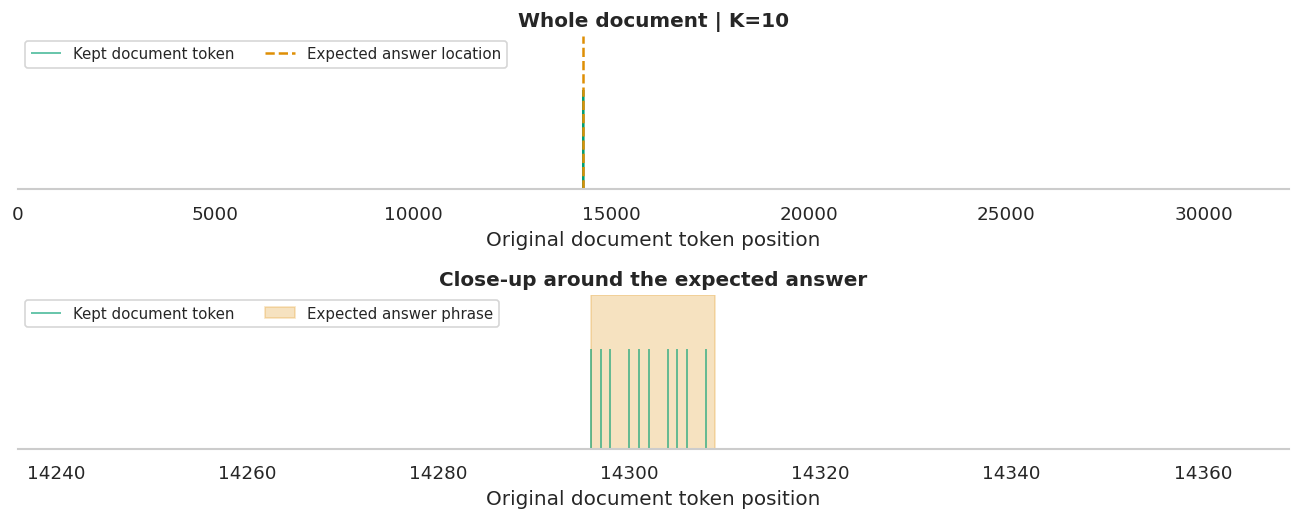

Expected-answer tokens kept: 10/13

In [25]:
pruned_budgets = [budget for budget in keep_budgets if budget is not None]
if not pruned_budgets:
    raise ValueError("Include an integer keep-budget to inspect token selection.")

inspection_budget = min(pruned_budgets)
inspection_output = outputs_by_budget[inspection_budget][-1]
kept_document_positions = [
    position for position in inspection_output.kept_pos[0]
    if document_start <= position < document_end
]
relative_positions = [
    position - document_start for position in kept_document_positions
]

figure, axes = plt.subplots(2, 1, figsize=(11, 4.5))
for axis in axes:
    sns.rugplot(
        x=relative_positions, height=0.65, expand_margins=False,
        color="#029e73", alpha=0.7, linewidth=1, ax=axis,
        label="Kept document token",
    )
    axis.set_yticks([])
    axis.grid(False)
    axis.set_xlabel("Original document token position")
    sns.despine(ax=axis, left=True)

axes[0].set_xlim(0, num_document_tokens)
axes[0].axvline(
    (answer_token_start + answer_token_end) / 2,
    color="#de8f05", linestyle="--", label="Expected answer location",
)
axes[0].set_title(f"Whole document | K={inspection_budget}")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=9)

axes[1].axvspan(
    answer_token_start, answer_token_end,
    color="#de8f05", alpha=0.25, label="Expected answer phrase",
)
axes[1].set_xlim(
    max(0, answer_token_start - 60), min(num_document_tokens, answer_token_end + 60)
)
axes[1].set_title("Close-up around the expected answer")
axes[1].legend(loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=9)
figure.tight_layout()
plt.show()

num_answer_tokens_kept = len(set(answer_token_positions) & set(kept_document_positions))
notebook_console.print(
    f"Expected-answer tokens kept: {num_answer_tokens_kept}/{len(answer_token_positions)}"
)

Let's read the selected tokens in their original order.

In [26]:
def group_consecutive_positions(positions: Sequence[int]) -> list[list[int]]:
    """Groups neighboring token positions without joining across gaps.

    Args:
        positions: Token positions in strictly increasing order.

    Returns:
        Consecutive runs in their original order, or an empty list if there
        are no positions. For example, [1, 2, 5] becomes [[1, 2], [5]].
    """
    groups: list[list[int]] = []
    for position in positions:
        if groups and position == groups[-1][-1] + 1:
            groups[-1].append(position)
        else:
            groups.append([position])
    return groups

In [27]:
selected_fragments = []
for position_group in group_consecutive_positions(kept_document_positions):
    token_group = [clean_token_ids[position] for position in position_group]
    fragment = tokenizer.decode(token_group, skip_special_tokens=True)
    selected_fragments.append(fragment)

selected_text = " … ".join(selected_fragments)
notebook_console.print(panel.Panel(
    text.Text(selected_text),
    title=f"Selected document text | K={inspection_budget}",
    border_style="green",
))
notebook_console.print("Expected answer:", text.Text(reference_answer))

╭───────────────────────────────── Selected document text | K=10 ──────────────────────────────────╮
│  eat a sandwich …  sit in Dol …  Park on a …  day                                                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

Expected answer: eat a sandwich and sit in Dolores Park on a sunny day

Compare the selected fragments with the expected answer and the model's
generated answer. Keeping the answer's words is useful evidence about what
the gate selected, but this view is not a complete explanation of its decision.
The model processes internal token representations, which can already contain
information from other tokens before pruning.

## What did this run show?

The main takeaway is how to judge a token budget: **check the answer, then
compare the amount of document kept and the prefill time**. The cell below
summarizes your measurements. It will report a failed reference, failed
retrieval at smaller budgets, or a slowdown if that is what occurred.

In [28]:
baseline_passed = results.loc["All", "Answer check"] == "Pass"
successful_budgets = [
    budget for budget in keep_budgets
    if budget is not None
    and budget < num_document_tokens
    and results.loc[str(budget), "Answer check"] == "Pass"
]
if not baseline_passed:
    takeaway = (
        "The All reference did not pass every answer check. Inspect its generated "
        "answers first: this run does not establish that pruning preserves a "
        "reliably retrieved answer."
    )
elif not successful_budgets:
    takeaway = (
        "The All reference passed, but no smaller tested budget passed every "
        "answer check. These measurements do not show a smaller budget that "
        "preserves retrieval for this question. Try a larger budget or inspect "
        "the generated answers for paraphrases missed by the check."
    )
else:
    smallest_successful_budget = min(successful_budgets)
    measured = results.loc[str(smallest_successful_budget)]
    time_change = 100 * (measured["Prefill (ms)"] / baseline_prefill_ms - 1)
    timing_description = (
        f"{abs(time_change):.1f}% lower" if time_change < 0
        else f"{time_change:.1f}% higher" if time_change > 0
        else "unchanged"
    )
    takeaway = (
        f"For this question, K={smallest_successful_budget:,} was the smallest "
        f"tested budget whose answer check passed in all {num_repeats} repeats. "
        f"It kept {measured['Document kept (%)']:.2f}% of the document tokens "
        "for the later layers. "
        f"Median prefill time was {measured['Prefill (ms)']:.1f} ms, versus "
        f"{baseline_prefill_ms:.1f} ms for All ({timing_description}). "
        "This is the smallest passing budget we tested, not necessarily the fastest."
    )
notebook_console.print(panel.Panel(
    text.Text(takeaway), title="What your measurements show", border_style="cyan"
))

╭────────────────────────────────── What your measurements show ───────────────────────────────────╮
│ For this question, K=100 was the smallest tested budget whose answer check passed in all 3       │
│ repeats. It kept 0.31% of the document tokens for the later layers. Median prefill time was      │
│ 436.9 ms, versus 6363.0 ms for All (93.1% lower). This is the smallest passing budget we tested, │
│ not necessarily the fastest.                                                                     │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

**Try a different question and document.** Change `sample_index` to a value
from 1 to 4 and rerun from “Look at the document and question.” Each document
has a different question and answer location. Does the same K still work?

For more examples, run `python examples/niah_demo.py --gate-attn flex` in a
compatible environment. For the broader evaluation, see the
[TokenGate paper](https://arxiv.org/abs/2610.26754) and the repository's
[benchmark instructions](https://github.com/token-gate-llms/TokenGate#-reproducing-results).